# UrbanHub – Partie 3 : analyse de la pollution de l'air

**Personne C – flux IoT (OpenAQ)**

Ce notebook répond aux 4 questions métier de l'énoncé à partir du Data Lake :

1. Quelles zones présentent les niveaux de pollution les plus élevés ?
2. Existe-t-il une variation journalière de la pollution ?
3. Quels polluants sont les plus dominants (analyse détaillée sur Paris) ?
4. Peut-on identifier des épisodes de pollution anormale ? (IA : z-score et Isolation Forest, comparaison aux seuils de l'OMS)

**Données utilisées**

- `gold/pollution/pollution_ville_heure.parquet` : une ligne par ville et par heure (moyenne des capteurs de la ville) ;
- `silver/pollution/` : une ligne par capteur et par mesure, pour les analyses par station.

Les données sont stockées en UTC ; les graphiques sont affichés à l'heure de Paris (règle du contrat).

## 0. Connexion au Data Lake et chargement

In [1]:
import io
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import dotenv_values

# Le notebook est dans partie3_pollution/ : la racine du dépôt est le dossier parent
RACINE = Path.cwd().parent if Path.cwd().name == "partie3_pollution" else Path.cwd()
sys.path.insert(0, str(RACINE))

# Depuis le PC (et non depuis Docker), MinIO s'appelle localhost
env = dotenv_values(RACINE / ".env")
os.environ["MINIO_ENDPOINT"] = (env.get("MINIO_ENDPOINT") or "").replace("host.docker.internal", "localhost")

from partie3_pollution.stockage import Lac

lac = Lac()
print("Stockage :", lac.mode())

FIGURES = RACINE / "partie3_pollution" / "figures"
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 1)

def sauver(nom):
    """Enregistre la figure courante dans partie3_pollution/figures/ (pour le rapport)."""
    plt.tight_layout()
    plt.savefig(FIGURES / f"{nom}.png", dpi=120)
    plt.show()

Stockage : MinIO (localhost:9000)


In [2]:
%pip install pyarrow pandas minio python-dotenv matplotlib scikit-learn 
gold = pd.read_parquet(io.BytesIO(lac.lire("gold", "pollution/pollution_ville_heure.parquet")))

colonnes_silver = ["ville", "timestamp", "sensor_id", "location_name", "pollutant", "value"]
fichiers = [f for f in lac.lister("silver", "pollution/") if f.endswith(".parquet")]
silver = pd.concat([pd.read_parquet(io.BytesIO(lac.lire("silver", f)), columns=colonnes_silver)
                    for f in fichiers], ignore_index=True)

# Heure de Paris pour l'affichage (le stockage reste en UTC)
gold["heure_paris"] = gold["heure"].dt.tz_convert("Europe/Paris")
silver["heure_paris"] = silver["timestamp"].dt.tz_convert("Europe/Paris")

print(f"Gold   : {len(gold):,} lignes ville-heure, du {gold['heure_paris'].min():%d/%m/%Y} au {gold['heure_paris'].max():%d/%m/%Y}")
print(f"Silver : {len(silver):,} mesures, {silver['sensor_id'].nunique()} capteurs, {len(fichiers)} fichiers journaliers")

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Gold   : 43,210 lignes ville-heure, du 01/11/2025 au 19/11/2026
Silver : 680,845 mesures, 254 capteurs, 377 fichiers journaliers


In [3]:
POLLUANTS = ["pm25", "pm10", "no2", "o3", "co"]
NOMS = {"pm25": "PM2.5", "pm10": "PM10", "no2": "NO2", "o3": "O3", "co": "CO"}
VILLES = ["Paris", "Lyon", "Marseille", "Toulouse", "Lille", "Bordeaux", "Nantes", "Strasbourg"]

# Lignes directrices de l'OMS (2021), en µg/m³
OMS_JOUR = {"pm25": 15, "pm10": 45, "no2": 25, "o3": 100, "co": 4000}   # 24 h (O3 : max de la moyenne sur 8 h)
OMS_AN = {"pm25": 5, "pm10": 15, "no2": 10}                              # moyenne annuelle

# Couverture : part des heures où chaque polluant est mesuré dans chaque ville
couverture = (gold.set_index("ville")[POLLUANTS].notna().groupby("ville").mean() * 100).reindex(VILLES)
print("Part des heures avec une mesure (%) :")
couverture.rename(columns=NOMS).round(0)

Part des heures avec une mesure (%) :


,PM2.5,PM10,NO2,O3,CO
ville,,,,,
Paris,100.0,100.0,100.0,100.0,0.0
Lyon,100.0,100.0,100.0,100.0,96.0
Marseille,100.0,86.0,57.0,57.0,57.0
Toulouse,100.0,100.0,47.0,47.0,0.0
Lille,100.0,100.0,100.0,99.0,0.0
Bordeaux,100.0,88.0,62.0,62.0,0.0
Nantes,91.0,91.0,93.0,99.0,0.0
Strasbourg,36.0,99.0,100.0,99.0,0.0


**Lecture :** une case proche de 0 % signifie que le polluant n'est pas mesuré dans la ville (il reste vide, jamais 0).
Le CO n'est mesuré que par très peu de stations en France : il sera analysé à part.

### Indicateur journalier comparable aux seuils de l'OMS

Les seuils journaliers de l'OMS ne se comparent pas à une valeur horaire :
- PM2.5, PM10, NO2, CO : **moyenne sur 24 h** ;
- O3 : **maximum de la moyenne glissante sur 8 h** de la journée.

Une journée n'est gardée que si au moins 18 heures sur 24 sont mesurées.

In [4]:
def indicateurs_journaliers(gold):
    resultats = []
    for ville, g in gold.groupby("ville"):
        h = g.set_index("heure_paris").sort_index()[POLLUANTS].asfreq("h")   # série horaire régulière
        nb = h.notna().resample("D").sum()
        jour = h.resample("D").mean()
        jour["o3"] = h["o3"].rolling(8, min_periods=6).mean().resample("D").max()
        jour = jour.where(nb >= 18)
        jour.insert(0, "ville", ville)
        resultats.append(jour)
    jours = pd.concat(resultats).reset_index().rename(columns={"heure_paris": "jour"})
    jours["jour"] = jours["jour"].dt.tz_localize(None)
    return jours

jours = indicateurs_journaliers(gold)
print(f"{len(jours):,} journées ville par ville")
jours.dropna(subset=["pm25", "no2"], how="all").tail()

2,308 journées ville par ville


,jour,ville,pm25,pm10,no2,o3,co
2302,2026-11-14,Toulouse,7.8,9.9,10.4,51.9,NaN
2303,2026-11-15,Toulouse,7.1,9.3,12.5,47.0,NaN
2304,2026-11-16,Toulouse,4.8,9.8,15.8,54.4,NaN
2305,2026-11-17,Toulouse,6.1,9.8,18.3,54.7,NaN
2306,2026-11-18,Toulouse,7.5,13.7,14.7,72.4,NaN


## 1. Quelles zones présentent les niveaux de pollution les plus élevés ?

On compare d'abord les **villes** (table Gold), puis les **stations** à l'intérieur des villes (table Silver).
Pour classer les villes sur plusieurs polluants, on calcule un **indice OMS** : la moyenne, sur PM2.5, PM10 et NO2,
du rapport « concentration moyenne / seuil annuel de l'OMS ». Un indice de 2 signifie « deux fois le seuil en moyenne ».

In [5]:
moyennes = gold.groupby("ville")[POLLUANTS].mean().reindex(VILLES)
rapport = pd.DataFrame({p: moyennes[p] / OMS_AN[p] for p in OMS_AN})
moyennes["indice_OMS"] = rapport.mean(axis=1)
classement = moyennes.sort_values("indice_OMS", ascending=False)
classement.rename(columns=NOMS)

,PM2.5,PM10,NO2,O3,CO,indice_OMS
ville,,,,,,
Paris,9.3,17.1,23.3,55.7,173.5,1.8
Lyon,9.3,16.7,19.5,55.9,202.6,1.6
Strasbourg,8.2,17.1,20.7,50.3,NaN,1.6
Lille,10.2,16.2,13.3,51.4,NaN,1.5
Bordeaux,6.9,21.2,13.9,74.9,NaN,1.4
Marseille,5.6,17.3,17.9,59.1,193.5,1.4
Toulouse,7.8,13.7,10.6,71.9,NaN,1.2
Nantes,7.1,12.7,4.1,61.6,156.0,0.9


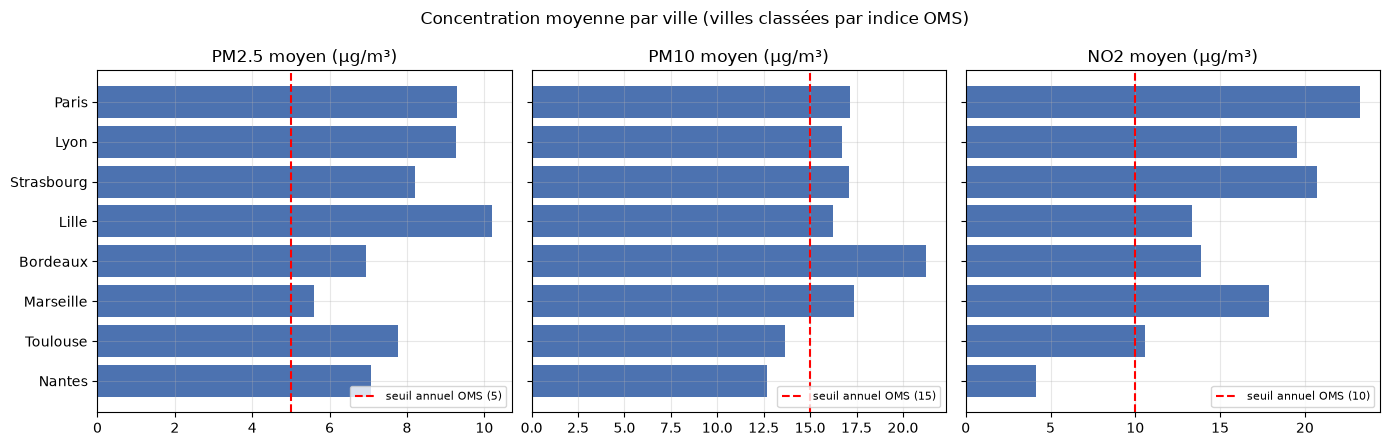

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
for ax, p in zip(axes, ["pm25", "pm10", "no2"]):
    s = classement[p]
    ax.barh(s.index, s.values, color="#4C72B0")
    ax.axvline(OMS_AN[p], color="red", ls="--", label=f"seuil annuel OMS ({OMS_AN[p]})")
    ax.set_title(f"{NOMS[p]} moyen (µg/m³)")
    ax.legend(loc="lower right", fontsize=8)
axes[0].invert_yaxis()
plt.suptitle("Concentration moyenne par ville (villes classées par indice OMS)")
sauver("q1_villes")

In [7]:
# Stations les plus polluées (12 derniers mois), pour PM2.5 et NO2
derniere = silver["timestamp"].max()
recent = silver[silver["timestamp"] >= derniere - pd.Timedelta(days=365)]
stations = (recent.groupby(["pollutant", "ville", "location_name"])["value"]
                  .agg(moyenne="mean", nb_mesures="count").reset_index())
stations = stations[stations["nb_mesures"] >= 24 * 30]          # au moins ~1 mois de mesures

for p in ["no2", "pm25"]:
    top = stations[stations["pollutant"] == p].nlargest(10, "moyenne")
    print(f"\nTop 10 des stations – {NOMS[p]} (µg/m³, seuil annuel OMS = {OMS_AN[p]})")
    display(top[["ville", "location_name", "moyenne", "nb_mesures"]].reset_index(drop=True))


Top 10 des stations – NO2 (µg/m³, seuil annuel OMS = 10)


,ville,location_name,moyenne,nb_mesures
0,Paris,Auto A1 -Saint-Denis,52.8,7411
1,Lyon,Lyon Périphérique,42.7,7373
2,Paris,Bld peripherique Est,39.6,7606
3,Lyon,A7 SUD LYONNAIS,32.8,7435
4,Paris,Place Victor Basch,30.2,7395
5,Paris,Quai des Celestins,28.4,6644
6,Paris,Place de l'Opéra,27.8,7294
7,Strasbourg,Strasbourg Clemenceau,26.3,7540
8,Paris,Boulevard Haussmann,26.2,7386
9,Paris,Rue Bonaparte,23.6,7596



Top 10 des stations – PM2.5 (µg/m³, seuil annuel OMS = 5)


,ville,location_name,moyenne,nb_mesures
0,Paris,Auto A1 -Saint-Denis,12.6,2961
1,Lille,Roubaix Serres,11.4,7181
2,Paris,Bld peripherique Est,10.8,2973
3,Lyon,LYON Centre,10.3,7202
4,Lyon,A7 SUD LYONNAIS,10.3,2938
5,Lille,Wattignies,10.0,7646
6,Paris,BOBIGNY,10.0,7554
7,Paris,LA DEFENSE,9.7,7155
8,Lille,Douai Theuriet,9.7,7253
9,Paris,VITRY-SUR-SEINE,9.6,7571


In [8]:
print("Classement des villes (indice OMS, du plus pollué au moins pollué) :")
for i, (ville, ligne) in enumerate(classement.iterrows(), 1):
    print(f"  {i}. {ville:<11} indice {ligne['indice_OMS']:.1f}  |  PM2.5 {ligne['pm25']:.1f}  PM10 {ligne['pm10']:.1f}  NO2 {ligne['no2']:.1f} µg/m³")

Classement des villes (indice OMS, du plus pollué au moins pollué) :
  1. Paris       indice 1.8  |  PM2.5 9.3  PM10 17.1  NO2 23.3 µg/m³
  2. Lyon        indice 1.6  |  PM2.5 9.3  PM10 16.7  NO2 19.5 µg/m³
  3. Strasbourg  indice 1.6  |  PM2.5 8.2  PM10 17.1  NO2 20.7 µg/m³
  4. Lille       indice 1.5  |  PM2.5 10.2  PM10 16.2  NO2 13.3 µg/m³
  5. Bordeaux    indice 1.4  |  PM2.5 6.9  PM10 21.2  NO2 13.9 µg/m³
  6. Marseille   indice 1.4  |  PM2.5 5.6  PM10 17.3  NO2 17.9 µg/m³
  7. Toulouse    indice 1.2  |  PM2.5 7.8  PM10 13.7  NO2 10.6 µg/m³
  8. Nantes      indice 0.9  |  PM2.5 7.1  PM10 12.7  NO2 4.1 µg/m³


**À retenir :** le classement des villes et les stations en tête (souvent des stations de trafic, au bord des grands axes,
pour le NO2) montrent où la pollution est la plus forte. Les écarts entre stations d'une même ville sont souvent plus grands
que les écarts entre villes : la pollution se concentre près des sources.

## 2. Existe-t-il une variation journalière de la pollution ?

On calcule le **profil moyen sur 24 h** (heure de Paris) de chaque polluant, toutes dates confondues.

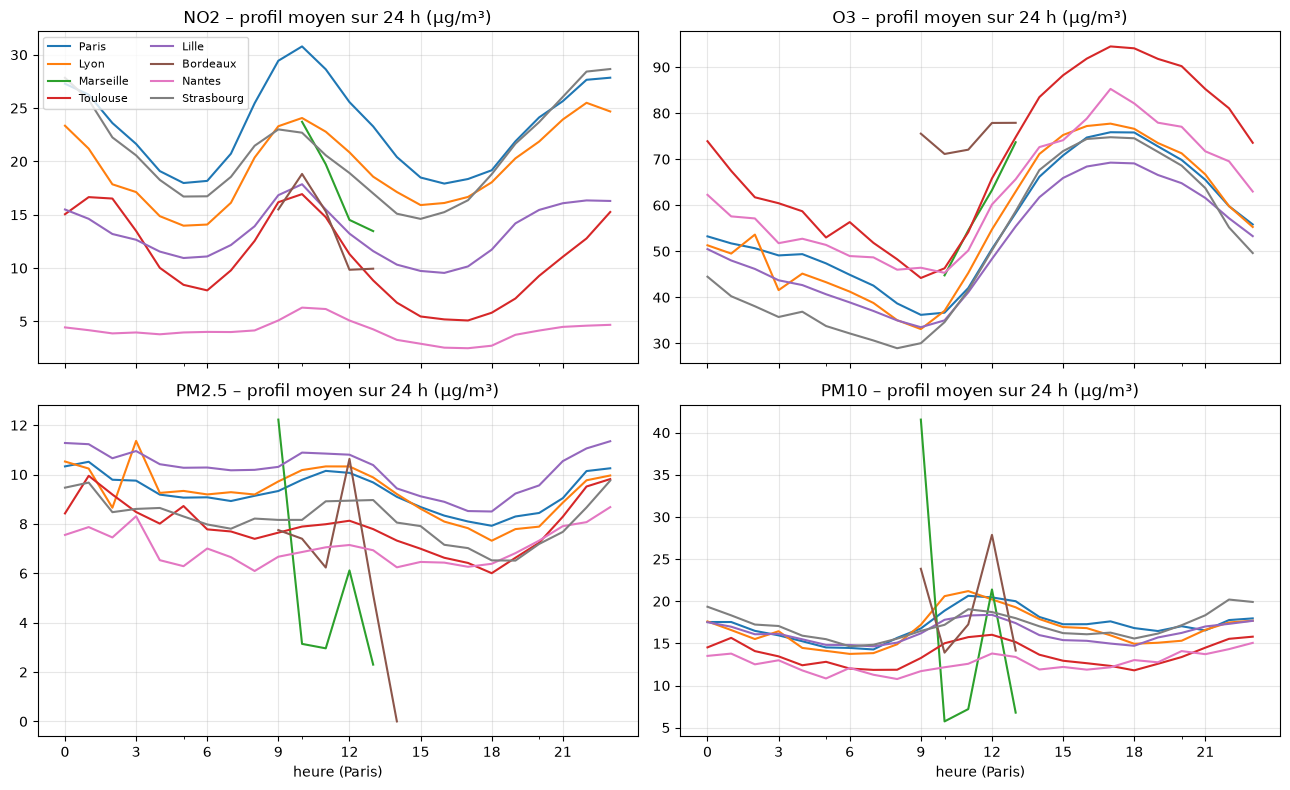

In [9]:
gold["heure_du_jour"] = gold["heure_paris"].dt.hour
gold["week_end"] = gold["heure_paris"].dt.dayofweek >= 5

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for ax, p in zip(axes.flat, ["no2", "o3", "pm25", "pm10"]):
    profil = gold.pivot_table(index="heure_du_jour", columns="ville", values=p, aggfunc="mean").reindex(columns=VILLES)
    profil.plot(ax=ax, lw=1.5, legend=False)
    ax.set_title(f"{NOMS[p]} – profil moyen sur 24 h (µg/m³)")
    ax.set_xlabel("heure (Paris)")
    ax.set_xticks(range(0, 24, 3))
axes[0, 0].legend(ncol=2, fontsize=8)
sauver("q2_profil_24h")

In [10]:
# Heures de pic et de creux, et amplitude (pic / creux), en moyenne sur toutes les villes
profil_moyen = gold.groupby("heure_du_jour")[POLLUANTS].mean()
resume = pd.DataFrame({
    "heure du pic": profil_moyen.idxmax(),
    "heure du creux": profil_moyen.idxmin(),
    "pic (µg/m³)": profil_moyen.max(),
    "creux (µg/m³)": profil_moyen.min(),
    "amplitude (pic/creux)": profil_moyen.max() / profil_moyen.min(),
}).rename(index=NOMS)
resume

,heure du pic,heure du creux,pic (µg/m³),creux (µg/m³),amplitude (pic/creux)
PM2.5,1,18,10.2,7.3,1.4
PM10,11,7,18.5,13.7,1.3
NO2,23,15,21.9,12.9,1.7
O3,17,9,77.3,35.5,2.2
CO,0,16,278.3,137.9,2.0


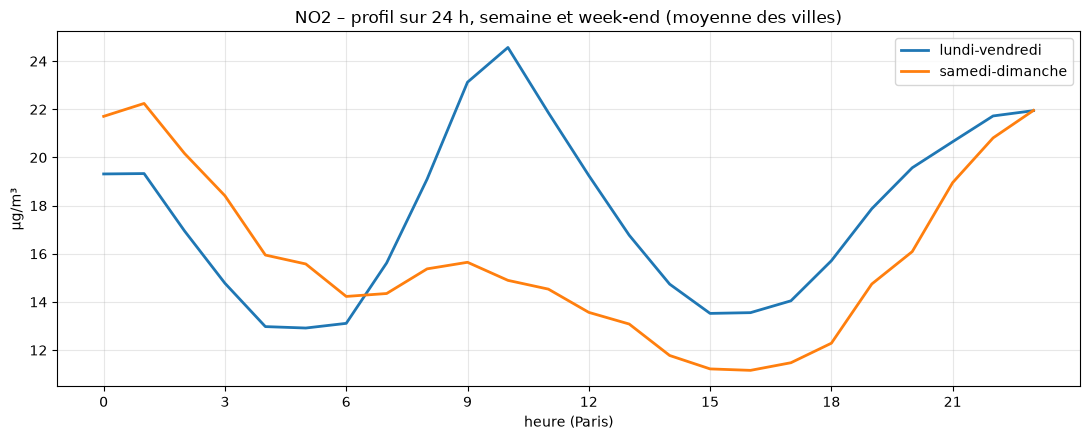

NO2 moyen : 17.6 µg/m³ en semaine, 15.8 µg/m³ le week-end (-10 %)


In [11]:
# NO2 : semaine contre week-end (effet du trafic)
fig, ax = plt.subplots()
for we, nom in [(False, "lundi-vendredi"), (True, "samedi-dimanche")]:
    gold[gold["week_end"] == we].groupby("heure_du_jour")["no2"].mean().plot(ax=ax, lw=2, label=nom)
ax.set_title("NO2 – profil sur 24 h, semaine et week-end (moyenne des villes)")
ax.set_xlabel("heure (Paris)"); ax.set_ylabel("µg/m³"); ax.set_xticks(range(0, 24, 3)); ax.legend()
sauver("q2_no2_semaine_weekend")

sem = gold[~gold["week_end"]]["no2"].mean(); we = gold[gold["week_end"]]["no2"].mean()
print(f"NO2 moyen : {sem:.1f} µg/m³ en semaine, {we:.1f} µg/m³ le week-end ({(we / sem - 1) * 100:+.0f} %)")

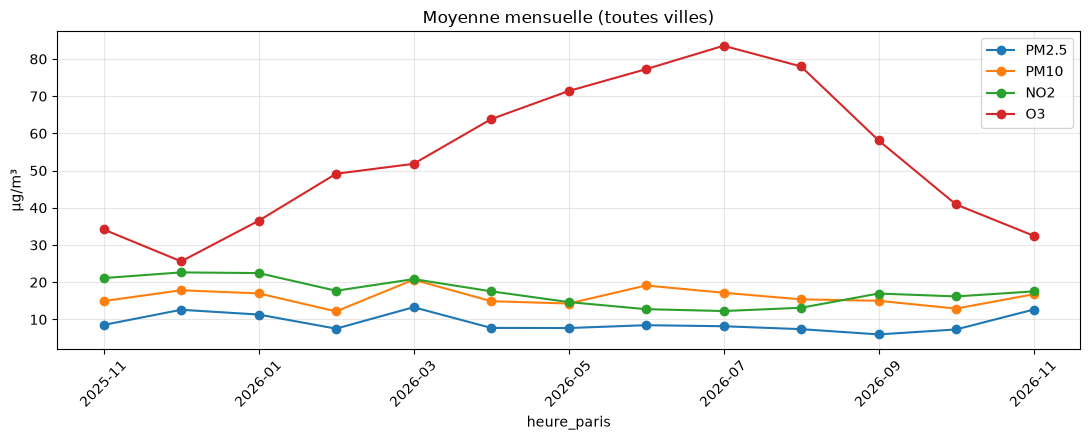

In [12]:
# Variation au fil de l'année (moyenne mensuelle de toutes les villes)
mensuel = gold.set_index("heure_paris")[["pm25", "pm10", "no2", "o3"]].resample("MS").mean()
mensuel.index = mensuel.index.strftime("%Y-%m")
mensuel.rename(columns=NOMS).plot(marker="o")
plt.title("Moyenne mensuelle (toutes villes)"); plt.ylabel("µg/m³"); plt.xticks(rotation=45)
sauver("q2_mensuel")

**À retenir :** la pollution varie fortement au cours de la journée, et chaque polluant a son propre rythme :
- le **NO2** (trafic) monte aux heures de pointe du matin et du soir, et baisse le week-end ;
- l'**O3** (ozone) est un polluant secondaire, formé par le soleil : il culmine l'après-midi et il est plus élevé en été ;
- les **particules** varient moins dans la journée, mais sont plus élevées en hiver (chauffage, inversions de température).

## 3. Quels polluants sont les plus dominants ?

« Dominant » peut se lire de deux façons :
- **en concentration** (µg/m³) : quel polluant est présent en plus grande quantité ;
- **en risque sanitaire** : quel polluant dépasse le plus souvent son seuil OMS. C'est la lecture la plus utile pour un décideur,
  car les seuils sont très différents d'un polluant à l'autre.

In [14]:
# Part des journées au-dessus du seuil journalier OMS, par ville et par polluant (%)
depassements = pd.DataFrame({
    p: jours.groupby("ville").apply(lambda g: (g[p] > OMS_JOUR[p]).sum() / g[p].notna().sum() * 100
                                    if g[p].notna().sum() else np.nan, include_groups=False)
    for p in POLLUANTS
}).reindex(VILLES)

def le_plus_grand(tableau):
    """Nom du polluant le plus élevé sur chaque ligne ("–" si la ville n'a aucune valeur)."""
    tableau = tableau.astype(float)
    return tableau.apply(lambda ligne: NOMS[ligne.idxmax()] if ligne.notna().any() else "–", axis=1)

principaux = ["pm25", "pm10", "no2", "o3"]
dominant = pd.DataFrame({
    "dominant en concentration": le_plus_grand(moyennes[principaux]),
    "dominant en risque (OMS)": le_plus_grand(depassements[principaux]),
    "% jours au-dessus OMS": depassements[principaux].astype(float).max(axis=1).round(0),
})
dominant

,dominant en concentration,dominant en risque (OMS),% jours au-dessus OMS
ville,,,
Paris,O3,NO2,38.0
Lyon,O3,O3,27.0
Marseille,O3,–,NaN
Toulouse,O3,O3,48.0
Lille,O3,PM2.5,17.0
Bordeaux,O3,–,NaN
Nantes,O3,O3,24.0
Strasbourg,O3,NO2,30.0


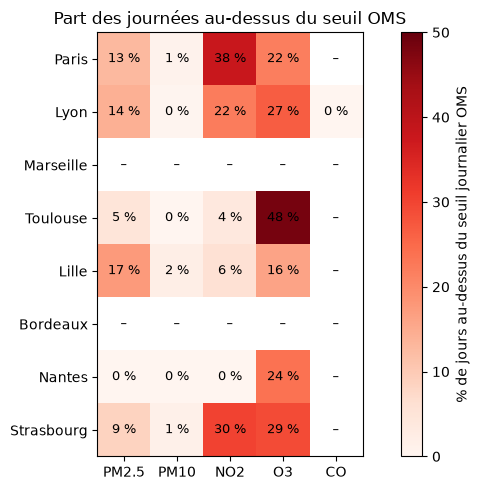

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
data = depassements.rename(columns=NOMS)
im = ax.imshow(data.values, cmap="Reds", vmin=0, vmax=max(50, np.nanmax(data.values)))
ax.set_xticks(range(len(data.columns)), data.columns); ax.set_yticks(range(len(data.index)), data.index)
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        v = data.values[i, j]
        ax.text(j, i, "–" if np.isnan(v) else f"{v:.0f} %", ha="center", va="center", fontsize=9,
                color="white" if v > 60 else "black")
ax.grid(False)
plt.colorbar(im, label="% de jours au-dessus du seuil journalier OMS")
ax.set_title("Part des journées au-dessus du seuil OMS")
sauver("q3_depassements_oms")

### Analyse détaillée : Paris

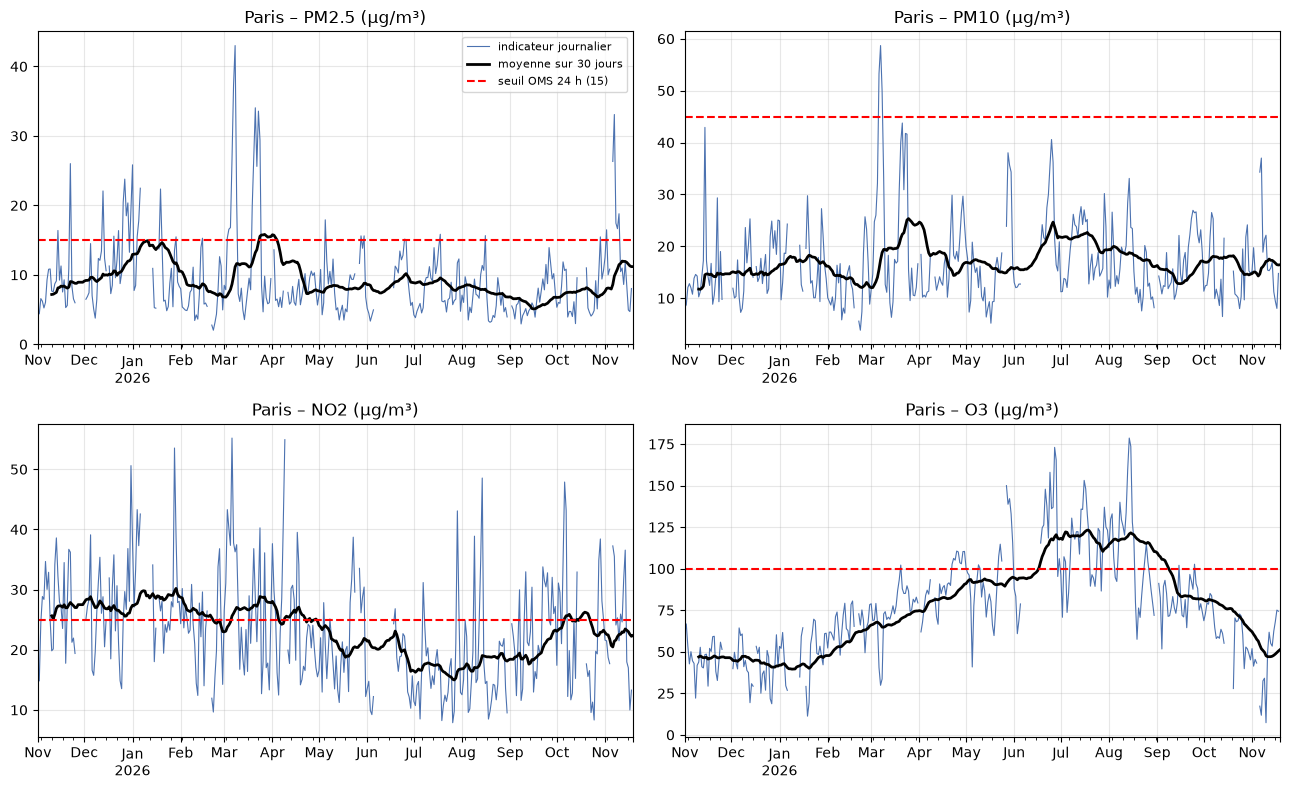

In [16]:
paris = gold[gold["ville"] == "Paris"].set_index("heure_paris").sort_index()
jours_paris = jours[jours["ville"] == "Paris"].set_index("jour")

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, p in zip(axes.flat, ["pm25", "pm10", "no2", "o3"]):
    jours_paris[p].plot(ax=ax, lw=0.8, color="#4C72B0", label="indicateur journalier")
    jours_paris[p].rolling(30, min_periods=10).mean().plot(ax=ax, lw=2, color="black", label="moyenne sur 30 jours")
    ax.axhline(OMS_JOUR[p], color="red", ls="--", label=f"seuil OMS 24 h ({OMS_JOUR[p]})")
    ax.set_title(f"Paris – {NOMS[p]} (µg/m³)"); ax.set_xlabel("")
axes[0, 0].legend(fontsize=8)
sauver("q3_paris_series")

In [17]:
print("Paris – statistiques par polluant (µg/m³) :")
stats_paris = pd.DataFrame({
    "moyenne": paris[POLLUANTS].mean(),
    "médiane": paris[POLLUANTS].median(),
    "max horaire": paris[POLLUANTS].max(),
    "seuil OMS 24 h": pd.Series(OMS_JOUR),
    "% jours > OMS": depassements.loc["Paris"],
    "moyenne / seuil annuel OMS": pd.Series({p: paris[p].mean() / OMS_AN[p] for p in OMS_AN}),
}).reindex(POLLUANTS).rename(index=NOMS)
stats_paris

Paris – statistiques par polluant (µg/m³) :


,moyenne,médiane,max horaire,seuil OMS 24 h,% jours > OMS,moyenne / seuil annuel OMS
PM2.5,9.3,7.5,59.7,15,12.8,1.9
PM10,17.1,14.7,207.7,45,0.9,1.1
NO2,23.3,19.9,102.0,25,37.9,2.3
O3,55.7,53.3,198.6,100,21.9,NaN
CO,173.5,175.0,176.0,4000,NaN,NaN


In [18]:
# Paris : stations (NO2) – trafic contre fond urbain
st_paris = stations[(stations["ville"] == "Paris")].pivot_table(index="location_name", columns="pollutant", values="moyenne")
st_paris = st_paris.rename(columns=NOMS).sort_values(st_paris.rename(columns=NOMS).columns[0], ascending=False)
print("Paris – moyenne sur 12 mois par station (µg/m³) :")
st_paris

Paris – moyenne sur 12 mois par station (µg/m³) :


pollutant,NO2,O3,PM10,PM2.5
location_name,,,,
Auto A1 -Saint-Denis,52.8,NaN,32.8,12.6
Bld peripherique Est,39.6,NaN,26.7,10.8
Place Victor Basch,30.2,NaN,23.6,NaN
Quai des Celestins,28.4,NaN,NaN,NaN
Place de l'Opéra,27.8,NaN,21.0,NaN
Boulevard Haussmann,26.2,NaN,21.4,8.9
Rue Bonaparte,23.6,NaN,NaN,NaN
AUBERVILLIERS,22.4,NaN,NaN,NaN
SAINT-DENIS,21.5,NaN,NaN,NaN


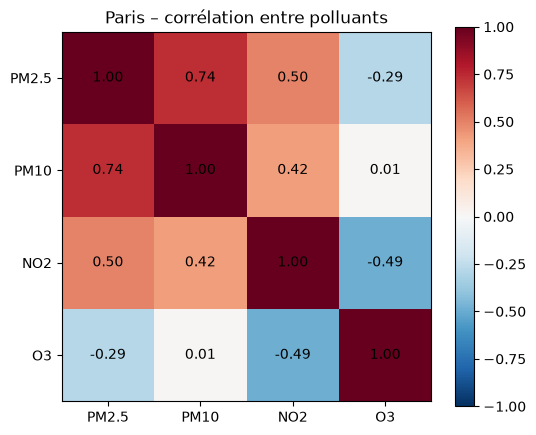

In [19]:
# Paris : liens entre polluants (corrélation des valeurs horaires)
corr = paris[["pm25", "pm10", "no2", "o3"]].rename(columns=NOMS).corr()
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(4), corr.columns); ax.set_yticks(range(4), corr.index); ax.grid(False)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center")
plt.colorbar(im); ax.set_title("Paris – corrélation entre polluants")
sauver("q3_paris_correlation")

**À retenir :**
- en **concentration**, l'O3 ou le NO2 sont souvent les plus présents ; mais l'O3 reste généralement sous son seuil journalier ;
- en **risque sanitaire**, les **particules fines PM2.5** et le **NO2** sont les polluants qui dépassent le plus souvent les seuils de l'OMS ;
- à Paris, PM2.5 et PM10 sont très corrélés (mêmes sources : chauffage, trafic, épisodes régionaux), tandis que le NO2 et l'O3
  évoluent en sens inverse (l'ozone est consommé par le NO émis par le trafic).

## 4. Peut-on identifier des épisodes de pollution anormale ? (IA)

On travaille sur l'**indicateur journalier** de chaque ville. Deux méthodes de détection d'anomalies sont comparées :

1. **z-score robuste** (statistique) : pour chaque ville et chaque polluant, on compare la valeur du jour à la normale du moment
   (médiane glissante sur 31 jours) et on divise l'écart par la dispersion habituelle (MAD). Un jour est anormal si |z| > 3,5.
   L'intérêt de la médiane glissante : un jour d'hiver n'est pas comparé à un jour d'été.
2. **Isolation Forest** (apprentissage automatique non supervisé, scikit-learn) : le modèle regarde ensemble PM2.5, PM10, NO2 et O3
   et isole les journées dont la combinaison est inhabituelle. On lui demande de signaler les 2 % de jours les plus atypiques.

Enfin, on compare ces anomalies aux **seuils de l'OMS** : un épisode « anormal » n'est pas forcément dangereux, et l'inverse.

In [20]:
SEUIL_Z = 3.5
polluants_jour = ["pm25", "pm10", "no2", "o3"]

def zscore_robuste(serie):
    normale = serie.rolling(31, center=True, min_periods=10).median()
    ecart = serie - normale
    mad = ecart.abs().rolling(31, center=True, min_periods=10).median()
    return ecart / (1.4826 * mad)

z = []
for ville, g in jours.groupby("ville"):
    g = g.set_index("jour").sort_index()
    for p in polluants_jour:
        zz = zscore_robuste(g[p])
        z.append(pd.DataFrame({"ville": ville, "jour": g.index, "polluant": p, "valeur": g[p].values, "z": zz.values}))
z = pd.concat(z, ignore_index=True).dropna()
anomalies_z = z[z["z"] > SEUIL_Z].copy()        # on cherche les pics de pollution (z positif)
anomalies_z["seuil_OMS"] = anomalies_z["polluant"].map(OMS_JOUR)
anomalies_z["au-dessus OMS"] = anomalies_z["valeur"] > anomalies_z["seuil_OMS"]
print(f"z-score : {len(anomalies_z)} couples (jour, polluant) anormaux sur {len(z):,}")
anomalies_z.groupby(["ville", "polluant"]).size().unstack(fill_value=0).reindex(VILLES).rename(columns=NOMS)

z-score : 103 couples (jour, polluant) anormaux sur 6,145


polluant,NO2,O3,PM10,PM2.5
ville,,,,
Paris,4.0,0.0,4.0,12.0
Lyon,3.0,0.0,5.0,6.0
Marseille,NaN,NaN,NaN,NaN
Toulouse,3.0,0.0,7.0,7.0
Lille,3.0,0.0,13.0,14.0
Bordeaux,NaN,NaN,NaN,NaN
Nantes,NaN,NaN,NaN,NaN
Strasbourg,2.0,1.0,13.0,6.0


In [27]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

iso = []
for ville, g in jours.groupby("ville"):
    g = g.set_index("jour").sort_index()[polluants_jour]
    utiles = [p for p in polluants_jour if g[p].notna().mean() > 0.5]   # polluants bien mesurés dans la ville
    if not utiles:
        print(f"{ville} : aucun polluant assez mesuré, ville ignorée")
        continue
    X = g[utiles].dropna(thresh=max(1, len(utiles) - 1))                # on tolère un polluant manquant dans la journée
    X = X.fillna(X.median())
    if len(X) < 30:
        print(f"{ville} : seulement {len(X)} journées complètes, ville ignorée")
        continue
    Xs = StandardScaler().fit_transform(X)                              # mêmes échelles pour tous les polluants
    modele = IsolationForest(n_estimators=300, contamination=0.02, random_state=42).fit(Xs)
    res = X.copy()
    res["ville"] = ville
    res["score_anomalie"] = -modele.score_samples(Xs)                   # plus c'est grand, plus c'est atypique
    res["anormal"] = modele.predict(Xs) == -1
    iso.append(res.reset_index())

iso = pd.concat(iso, ignore_index=True) if iso else pd.DataFrame(columns=["jour", "ville", "score_anomalie", "anormal"])
anomalies_iso = iso[iso["anormal"] == True]
print(f"Isolation Forest : {len(anomalies_iso)} journées anormales sur {len(iso):,} ({iso['ville'].nunique()} villes analysées)")

Bordeaux : aucun polluant assez mesuré, ville ignorée
Marseille : aucun polluant assez mesuré, ville ignorée
Nantes : aucun polluant assez mesuré, ville ignorée
Isolation Forest : 34 journées anormales sur 1,677 (5 villes analysées)


In [28]:
# Les deux méthodes sont-elles d'accord ?
jours_z = set(zip(anomalies_z["ville"], anomalies_z["jour"]))
jours_iso = set(zip(anomalies_iso["ville"], anomalies_iso["jour"]))
communs = jours_z & jours_iso
print(f"Jours anormaux selon le z-score         : {len(jours_z)}")
print(f"Jours anormaux selon l'Isolation Forest : {len(jours_iso)}")
print(f"Jours détectés par les deux méthodes    : {len(communs)}"
      f"  ({len(communs) / max(1, len(jours_iso)) * 100:.0f} % des jours Isolation Forest)")

# Comparaison avec l'OMS : parmi les anomalies, combien dépassent aussi le seuil ?
part = anomalies_z.groupby("polluant")["au-dessus OMS"].mean().mul(100).rename(index=NOMS)
print("\nPart des anomalies (z-score) qui dépassent aussi le seuil journalier OMS :")
print(part.round(0).astype(int).astype(str).add(" %").to_string())

Jours anormaux selon le z-score         : 73
Jours anormaux selon l'Isolation Forest : 34
Jours détectés par les deux méthodes    : 22  (65 % des jours Isolation Forest)

Part des anomalies (z-score) qui dépassent aussi le seuil journalier OMS :
polluant
NO2       80 %
O3       100 %
PM10      24 %
PM2.5     91 %


In [30]:
# Regrouper les jours anormaux consécutifs (même ville, même polluant) en épisodes
a = anomalies_z.sort_values(["ville", "polluant", "jour"]).copy()
a["nouvel_episode"] = a.groupby(["ville", "polluant"])["jour"].diff() != pd.Timedelta(days=1)
a["episode"] = a["nouvel_episode"].cumsum()
episodes = a.groupby("episode").agg(
    ville=("ville", "first"), polluant=("polluant", "first"),
    debut=("jour", "min"), fin=("jour", "max"), nb_jours=("jour", "count"),
    pic=("valeur", "max"), z_max=("z", "max"))
episodes["pic / seuil OMS"] = episodes["pic"] / episodes["polluant"].map(OMS_JOUR)
episodes["polluant"] = episodes["polluant"].map(NOMS)
episodes["vu aussi par Isolation Forest"] = [
    any((e.ville, d) in jours_iso for d in pd.date_range(e.debut, e.fin)) for e in episodes.itertuples()]
episodes = episodes.sort_values("pic / seuil OMS", ascending=False).reset_index(drop=True)
print(f"{len(episodes)} épisodes de pollution anormale. Les 15 plus graves (rapport au seuil OMS) :")
episodes.head(15)

79 épisodes de pollution anormale. Les 15 plus graves (rapport au seuil OMS) :


,ville,polluant,debut,fin,nb_jours,pic,z_max,pic / seuil OMS,vu aussi par Isolation Forest
0,Lille,PM2.5,2026-03-07,2026-03-08,2,48.7,5.2,3.2,True
1,Lille,PM2.5,2026-01-26,2026-01-26,1,46.6,7.3,3.1,True
2,Paris,PM2.5,2026-03-07,2026-03-08,2,43.0,4.8,2.9,True
3,Lille,PM2.5,2026-03-23,2026-03-24,2,42.5,5.4,2.8,False
4,Lille,PM2.5,2026-03-20,2026-03-20,1,39.3,3.8,2.6,True
5,Lyon,PM2.5,2026-01-02,2026-01-02,1,38.6,3.6,2.6,True
6,Lille,PM2.5,2026-11-07,2026-11-07,1,36.9,3.6,2.5,False
7,Paris,PM2.5,2026-03-20,2026-03-24,5,34.0,7.9,2.3,True
8,Paris,PM2.5,2026-11-07,2026-11-07,1,33.1,4.1,2.2,True
9,Strasbourg,PM2.5,2026-11-06,2026-11-08,3,33.1,5.4,2.2,False


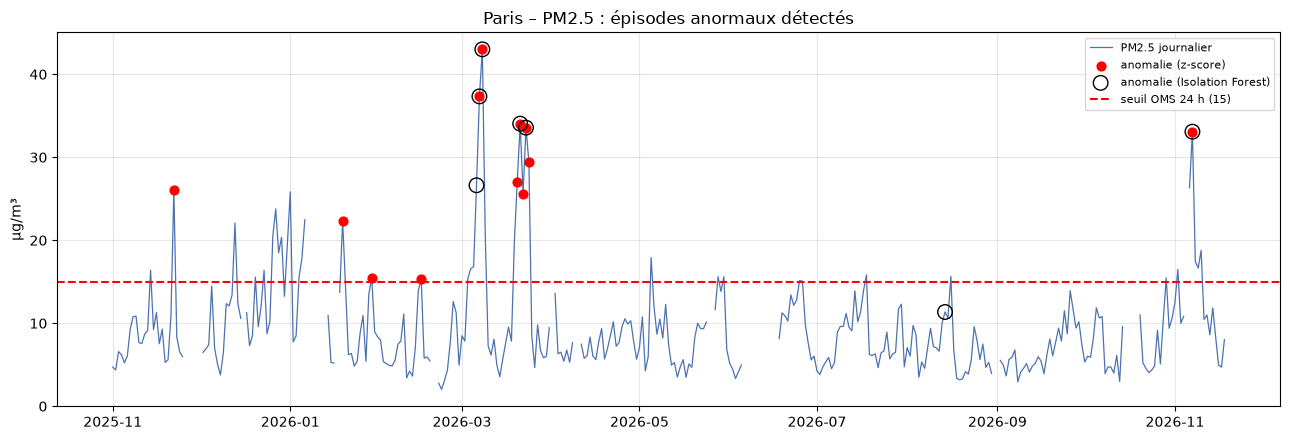

In [29]:
# Visualisation : PM2.5 à Paris, anomalies et seuil OMS
p, ville = "pm25", "Paris"
serie = jours[jours["ville"] == ville].set_index("jour")[p]
anos = anomalies_z[(anomalies_z["ville"] == ville) & (anomalies_z["polluant"] == p)]
iso_v = anomalies_iso[anomalies_iso["ville"] == ville]

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(serie.index, serie.values, lw=0.9, color="#4C72B0", label=f"{NOMS[p]} journalier")
ax.scatter(anos["jour"], anos["valeur"], color="red", s=40, zorder=3, label="anomalie (z-score)")
ax.scatter(iso_v["jour"], serie.reindex(iso_v["jour"]).values, facecolors="none", edgecolors="black", s=110,
           zorder=3, label="anomalie (Isolation Forest)")
ax.axhline(OMS_JOUR[p], color="red", ls="--", label=f"seuil OMS 24 h ({OMS_JOUR[p]})")
ax.set_title(f"{ville} – {NOMS[p]} : épisodes anormaux détectés"); ax.set_ylabel("µg/m³"); ax.set_xlabel(""); ax.legend(fontsize=8)
sauver("q4_paris_pm25_anomalies")

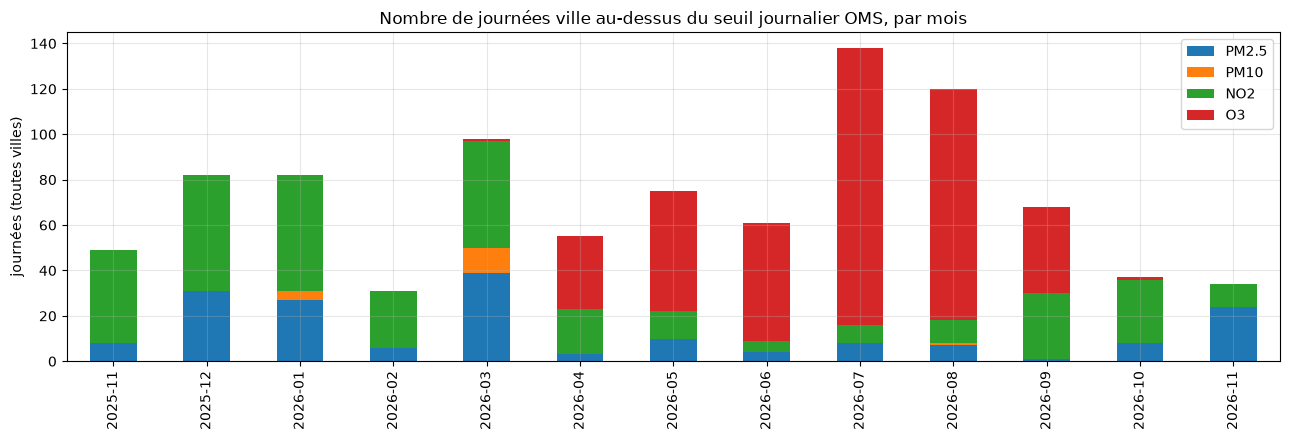

In [25]:
# Nombre de jours au-dessus du seuil OMS par mois (toutes villes) : quand ont lieu les épisodes ?
dep = jours.set_index("jour")[polluants_jour].gt(pd.Series(OMS_JOUR)[polluants_jour])
dep_mois = dep.groupby(dep.index.to_period("M")).sum()
dep_mois.index = dep_mois.index.astype(str)
dep_mois.rename(columns=NOMS).plot(kind="bar", stacked=True, figsize=(13, 4.5))
plt.title("Nombre de journées ville au-dessus du seuil journalier OMS, par mois")
plt.ylabel("journées (toutes villes)"); plt.xlabel("")
sauver("q4_depassements_par_mois")

**À retenir :**
- les deux méthodes repèrent les mêmes grands épisodes ; l'Isolation Forest voit en plus des combinaisons inhabituelles
  (par exemple beaucoup de particules mais peu de NO2), le z-score dit précisément quel polluant est en cause ;
- un jour « anormal » n'est pas toujours au-dessus du seuil OMS (une hausse forte mais depuis un niveau bas), et des jours
  au-dessus du seuil ne sont pas anormaux (pollution chronique, par exemple le NO2 près du trafic) :
  **les deux informations sont complémentaires** pour une alerte ;
- les épisodes de particules se concentrent en hiver et au début du printemps, ceux d'ozone en été (chaleur et soleil).

## Synthèse automatique des résultats

In [31]:
print("1. Zones les plus polluées")
print(f"   Villes en tête (indice OMS) : {', '.join(classement.index[:3])} ; la moins polluée : {classement.index[-1]}.")
top_no2 = stations[stations['pollutant'] == 'no2'].nlargest(1, 'moyenne').iloc[0]
print(f"   Station la plus polluée en NO2 : {top_no2['location_name']} ({top_no2['ville']}), {top_no2['moyenne']:.1f} µg/m³ en moyenne.")

print("\n2. Variation journalière")
for p in ["no2", "o3", "pm25"]:
    print(f"   {NOMS[p]} : pic vers {profil_moyen[p].idxmax()} h, creux vers {profil_moyen[p].idxmin()} h "
          f"(pic = {profil_moyen[p].max() / profil_moyen[p].min():.1f} x le creux).")
print(f"   NO2 : {(we / sem - 1) * 100:+.0f} % le week-end par rapport à la semaine.")

print("\n3. Polluants dominants")
print("   En risque sanitaire (plus souvent au-dessus du seuil OMS) :",
      dominant["dominant en risque (OMS)"].value_counts().to_dict())
print(f"   Paris : {depassements.loc['Paris', 'pm25']:.0f} % des jours au-dessus du seuil OMS en PM2.5, "
      f"{depassements.loc['Paris', 'no2']:.0f} % en NO2.")

print("\n4. Épisodes anormaux")
print(f"   {len(episodes)} épisodes détectés (z-score), dont {int(episodes['vu aussi par Isolation Forest'].sum())} "
      f"confirmés par l'Isolation Forest.")
e = episodes.iloc[0]
print(f"   Le plus grave : {e['polluant']} à {e['ville']} du {e['debut']:%d/%m/%Y} au {e['fin']:%d/%m/%Y}, "
      f"pic {e['pic']:.0f} µg/m³ ({e['pic / seuil OMS']:.1f} x le seuil OMS).")
print(f"\nFigures enregistrées dans : {FIGURES}")

1. Zones les plus polluées
   Villes en tête (indice OMS) : Paris, Lyon, Strasbourg ; la moins polluée : Nantes.
   Station la plus polluée en NO2 : Auto A1 -Saint-Denis (Paris), 52.8 µg/m³ en moyenne.

2. Variation journalière
   NO2 : pic vers 23 h, creux vers 15 h (pic = 1.7 x le creux).
   O3 : pic vers 17 h, creux vers 9 h (pic = 2.2 x le creux).
   PM2.5 : pic vers 1 h, creux vers 18 h (pic = 1.4 x le creux).
   NO2 : -10 % le week-end par rapport à la semaine.

3. Polluants dominants
   En risque sanitaire (plus souvent au-dessus du seuil OMS) : {'O3': 3, 'NO2': 2, '–': 2, 'PM2.5': 1}
   Paris : 13 % des jours au-dessus du seuil OMS en PM2.5, 38 % en NO2.

4. Épisodes anormaux
   79 épisodes détectés (z-score), dont 30 confirmés par l'Isolation Forest.
   Le plus grave : PM2.5 à Lille du 07/03/2026 au 08/03/2026, pic 49 µg/m³ (3.2 x le seuil OMS).

Figures enregistrées dans : c:\Users\selfa\Desktop\DataLake\UrbanHub\partie3_pollution\figures
